<a href="https://colab.research.google.com/github/ascr0wn/google_colab_notebooks/blob/main/01_dl_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Douts/questions:
1. what exactly does numpy and pytorch freezes when we set a manual seed in them in our pipeline!?
2. explain: "the vectorized line is dramatically faster, typically by tens of times. NumPy and PyTorch run whole-array operations in optimized compiled code, which is why a training loop works on batches and not on one number at a time"
3.
'''

'\nDouts/questions:\n1. what exactly does numpy and pytorch freezes when we set a manual seed in them in our pipeline!?\n2. explain: "the vectorized line is dramatically faster, typically by tens of times. NumPy and PyTorch run whole-array operations in optimized compiled code, which is why a training loop works on batches and not on one number at a time"\n3.\n'

In [ ]:
### 0.1 - Setup ###

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("Torch Version: ", torch.__version__)
print("Numpy version: ", np.__version__)
print("GPU Available: ", torch.cuda.is_available())

Torch Version:  2.11.0+cu130
Numpy version:  2.1.3
GPU Available:  True


In [ ]:
import random

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED) #weight initialization, dropout, data shuffling, random augmentation, random sampling

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device: ", device)

Using Device:  cuda


In [ ]:
x = torch.rand(3,4) #pytorch tensor 3 rows, 4 columns, filled with random values [0,1)
print("x", x)
print("x's shape: ", x.shape)
print("x's device: ", x.device) #by default it is allotted on a cpu
x = x.to(device) #change allocation to device(here a cuda gpu)
print("x's new device: ", x.device)

x tensor([[0.5349, 0.1988, 0.6592, 0.6569],
        [0.2328, 0.4251, 0.2071, 0.6297],
        [0.3653, 0.8513, 0.8549, 0.5509]])
x's shape:  torch.Size([3, 4])
x's device:  cpu
x's new device:  cuda:0


In [ ]:
### 0.2 - NUMPY ###

In [ ]:
a = np.array([1, 2, 3])
b = np.array([[1,2,3],[4,5,6]])
c = np.zeros((3,3))
d = np.random.rand(3,2)

print(a.shape, a.dtype, a.ndim)
print(b.shape, b.dtype, b.ndim)
print(c.shape, c.dtype, c.ndim)
print(d.shape, d.dtype, d.ndim)

(3,) int64 1
(2, 3) int64 2
(3, 3) float64 2
(3, 2) float64 2


In [ ]:
e = np.arange(12)
e = e.reshape(3,4)
print(e.shape, e.dtype, e.ndim, "\n")
print(e, "\n")
print(e[1,:], "\n")
print(e[:,3], "\n")
print(e[2,2], "\n")
print(e[1:,:2], "\n")
print(e.reshape(-1,2).shape) #find number of rows on your own, but number of columns are 2, eg: can we used to flatten an image (28x28 -> 784)

(3, 4) int64 2 

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 

[4 5 6 7] 

[ 3  7 11] 

10 

[[4 5]
 [8 9]] 

(6, 2)


In [ ]:
f = np.random.rand(100) #increase the number to see a bigger differnce!
%timeit sum(v*2 for v in f) # using loops is slow
%timeit (f*2).sum() # numpy (compiled optimised code) is faster

19.2 µs ± 345 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)
2.94 µs ± 78.1 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


In [ ]:
g = np.arange(12).reshape(3,4) # (3,4) matrix with values [0-11]
print(g.sum())
print(g.sum(axis=0)) #sums columns wise, drops row axis so shape becomes (4,)
print(g.sum(axis=1)) #sums row wise, drops column axis so shape becomes (3,)
print(g.max(axis=0)) #max in every column, shape (4,)
print(g.argmax(axis=1)) #index of max in every row (3,)

66
[12 15 18 21]
[ 6 22 38]
[ 8  9 10 11]
[3 3 3]


In [ ]:
h = np.array([[1,2,3], [4,5,6]]) # shape: 2x3
i = np.array([1,2]) # shape: 2,
j = np.array([[1], [2]]) # shape: 2x1
k = np.array([1,2,3]) #shape: 3,
print(h+j, "\n", h+k) #h+i is bad, doesn't match!
# broadcast!, mostly used for adding bias. stretches dimention if not matched in special conditions only.
# start from right dimention (column), it's good if dimention matches or one of them is 1 (stretch), else not good!
#eg: 2x3 with 2,: bad (2 not match with 3), 2x3 with 2x1: good(3 with 1 and 2 with 2), 2x3 with 3,:good (3 matches with 3)

[[2 3 4]
 [6 7 8]] 
 [[2 4 6]
 [5 7 9]]


In [ ]:
'''
3 features/inputs, 2 neurons in hidden layer, if batch size is 4 then input is 4x3 matrix, weight matrix would be
3x2, bias is 2, then final input to neurons is a 4x2 matrix where rows are sample number and columns decide neuron
number. for example row 3 column 2 is 3rd sample for neuron 2.
here bias is broadcasted to all rows of matrix 4x2.
finally 4x2 goes into activation function, let's say relu and we get activated 4x2 output.
'''

"\n3 features/inputs, 2 neurons in hidden layer, if batch size is 4 then input is 4x3 matrix, weight matrix would be\n3x2, bias is 2, then final input to neurons is a 4x2 matrix where rows are sample number and columns decide neuron\nnumber. for example row 3 column 2 is 3rd sample for neuron 2.\nhere bias is broadcasted to all rows of matrix 4x2.\nfinally 4x2 goes into activation function, let's say relu and we get activated 4x2 output.\n"

In [ ]:
l = np.array([[1, 2, 3],
             [2, 3, 1],
             [3, 1, 2]])

m = np.array([[1, 2],
             [2, 1],
             [2, 3]])

print(l@m) # this is matrix multiplication
#print(l*m) # this is overlap multiplication between matrices, element by element (can be broadcasted, if dimentions don't match)


[[11 13]
 [10 10]
 [ 9 13]]


In [ ]:
#Manual feedforward
np.random.seed(42)
X = np.random.rand(4,3)
W = np.random.rand(3,2)
b = np.random.rand(2,)
Z = X @ W + b
H = np.maximum(0,Z)
print("input: ", X, "shape: ", X.shape)
print("weights: ", W, "shape: ", W.shape)
print("bias: ", b, "shape: ", b.shape)
print("pre-activated output: ", Z, "shape: ", Z.shape)
print("post-activation: ", H, "shape: ", H.shape)

input:  [[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]
 [0.05808361 0.86617615 0.60111501]
 [0.70807258 0.02058449 0.96990985]] shape:  (4, 3)
weights:  [[0.83244264 0.21233911]
 [0.18182497 0.18340451]
 [0.30424224 0.52475643]] shape:  (3, 2)
bias:  [0.43194502 0.29122914] shape:  (2,)
pre-activated output:  [[1.13929526 0.92924248]
 [1.00612208 0.5288214 ]
 [0.82067332 0.77786214]
 [1.32020515 0.95432236]] shape:  (4, 2)
post-activation:  [[1.13929526 0.92924248]
 [1.00612208 0.5288214 ]
 [0.82067332 0.77786214]
 [1.32020515 0.95432236]] shape:  (4, 2)


In [ ]:
X = np.random.rand(100, 3) * 50 + 10
X_normalised = (X - X.mean(axis=0)) / X.std(axis=0)

In [ ]:
### --- pandas (loads and inspect data) and matplotlib (draws data) --- ###

In [ ]:
# We use Pandas DataFrames because they make data cleaning, filtering and column selection easier;
# we use NumPy arrays because they are better suited for fast numerical operations and matrix calculations.
# Basic difference: DataFrames have named rows and columns, whereas NumPy arrays mainly work with positional indices and don't inherently store column names.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
#Pandas: Explore, clean, select features, handle missing values, Numpy: Convert, normalize, split and transform
raw = load_breast_cancer(as_frame=True).frame
#original returns bunch object (data.data,.target,.feature_names,.target_names,.DESCR - they are all numpy ndarray, .DESCR is string
#as_frame=True returns still a bunch object but data.data(shape: axb),.target(shape: a,)(it is a series, not a dataframe),.frame(shape: axb+1) as pandas dataframe
#.frame changes it a dataframe complete which is data+target. no bunch object just 1 combined dataframe!
raw.to_csv("cancer.csv", index=False)
df = pd.read_csv("cancer.csv")
print("data shape: ", df.shape)
df.head()

data shape:  (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df.info() #number of rows and columns, column names, non-null values count/column, data types/column, memory usage
print(df.isna().sum().sum()) #flow-missing values per column summed to find total.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.describe() # column wise summaries like count(non missing values), mean, std, min, 25%, 50%, 75%, max(value)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [ ]:
s = df["mean radius"] #series not a dataframe
print(s.shape)
d = df[["mean radius", "mean area"]] #d is a dataframe
print(d.shape)
print(df.iloc[:4,:4]) #iloc[row_position, column_position]
big = df[df["mean radius"] > 20]
print(big.shape)

(569,)
(569, 2)
   mean radius  mean texture  mean perimeter  mean area
0        17.99         10.38          122.80     1001.0
1        20.57         17.77          132.90     1326.0
2        19.69         21.25          130.00     1203.0
3        11.42         20.38           77.58      386.1
(45, 31)


In [ ]:
print(df["target"].value_counts()) # to check whether the dataset is balanced or skewed
print(df["target"].value_counts(normalize=True).round(3)) #gives percentage out of 100 of each class

target
1    357
0    212
Name: count, dtype: int64
target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [ ]:
print(df.groupby("target")["mean radius"].mean()) #made 2 groups based on output classes, 0 and 1. then found out mean for column mean radius for those two groups.

target
0    17.462830
1    12.146524
Name: mean radius, dtype: float64


In [ ]:
X = df.drop(columns="target").to_numpy()
y = df["target"].to_numpy()
print("X shape: ", X.shape, "y shape: ", y.shape, "X dtype: ", X.dtype)

X shape:  (569, 30) y shape:  (569,) X dtype:  float64


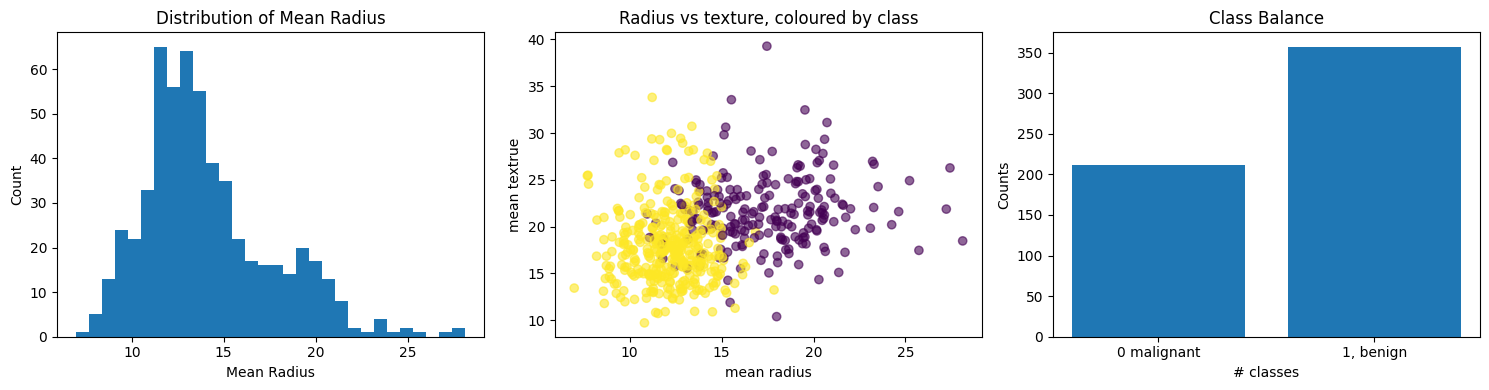

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15,4)) # fig mean canvas of size in inches, subplots (here 1 row, 3 columns) are actual graphs in the canvas.
axes[0].hist(df["mean radius"], bins=30) # bin controls how many groups (intervals) your data is devided into when plotting a histogram.
axes[0].set_title("Distribution of Mean Radius")
axes[0].set_xlabel("Mean Radius")
axes[0].set_ylabel("Count")

axes[1].scatter(df["mean radius"], df["mean texture"], c=df["target"], alpha=0.6) # x-axis, y-axis, c for color (different per class in "targer"), and alpha is transparency (as more points overlap transparency increases in the grpah).
axes[1].set_title("Radius vs texture, coloured by class")
axes[1].set_xlabel("mean radius")
axes[1].set_ylabel("mean textrue")

counts = df["target"].value_counts().sort_index()
axes[2].bar(["0 malignant", "1, benign"], counts.values) #x-axis, y-axis
axes[2].set_title("Class Balance")
axes[2].set_xlabel("# classes")
axes[2].set_ylabel("Counts")

plt.tight_layout() #automatically adjusts text and graphs so nothing overlaps with anything else and nothing is too tight!
plt.show()


min:  7


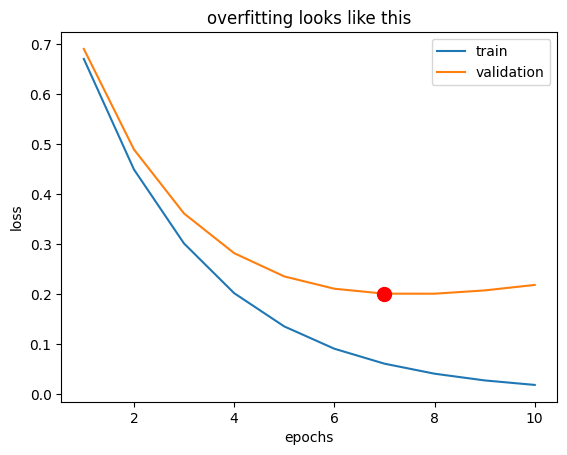

In [ ]:
epochs = np.arange(1,11)
train_loss = np.exp(-0.4 * epochs) #finds e^-0.4*epochs 10 times
val_loss = np.exp(-0.4 * epochs) + 0.02 * epochs
min_val_index = np.argmin(val_loss)
min_val_value = val_loss[min_val_index]
print("min: ", min_val_index)

plt.plot(epochs, train_loss, label="train")
plt.plot(epochs, val_loss, label="validation")
plt.scatter(min_val_index, min_val_value, color='red', s=100, zorder=5)
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend() #plt.legend() displays a legend that identifies what each plotted line or data series represents
plt.title("overfitting looks like this")
plt.show()

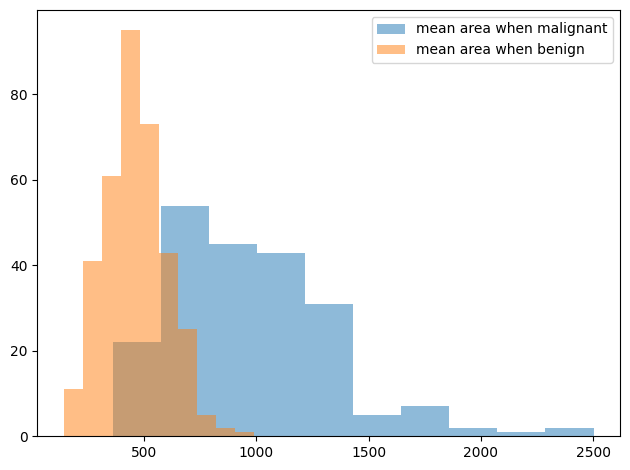

In [ ]:
'''
exercise 1: On a single plot, draw two overlaid histograms of mean area, one for malignant rows and one for benign rows. Use df[df["target"] == 0]["mean area"], alpha=0.5 and label=, then add plt.legend(). Predict first: which class has the larger areas?
'''
a = df[df["target"] == 0]["mean area"]
b = df[df["target"] == 1]["mean area"]
plt.hist(a, alpha=0.5, label="mean area when malignant")
plt.hist(b, alpha=0.5, label="mean area when benign")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
'''
exercise 2: Run df.corr()["target"].sort_values(). Which 3 features have the strongest negative correlation with target? Explain why a negative sign makes sense when 0 means malignant.
'''
df.corr()["target"].sort_values()

,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636
worst area,-0.733825
mean radius,-0.730029
mean area,-0.708984
mean concavity,-0.696360
worst concavity,-0.659610


In [ ]:
'''
exercise 3: In Cell 8, find the epoch with the lowest validation loss using np.argmin(val_loss) + 1 (the +1 is there because epochs start at 1). Mark it on the plot with plt.axvline(...). This is the idea behind early stopping.
changes done above!
'''

'\nexercise 3: In Cell 8, find the epoch with the lowest validation loss using np.argmin(val_loss) + 1 (the +1 is there because epochs start at 1). Mark it on the plot with plt.axvline(...). This is the idea behind early stopping.\nchanges done above!\n'

In [ ]:
'''
# Dataset Exploration & Visualization — Questions and Answers

## Quiz

**Q1. What's the difference between `df["mean radius"]` and `df[["mean radius"]]`, in type and shape?**

**Answer:**
- `df["mean radius"]` returns a Pandas Series with shape `(569,)`.
- `df[["mean radius"]]` returns a Pandas DataFrame with shape `(569, 1)`.

Single brackets select a Series (1D); double brackets select a DataFrame (2D).

**Q2. Why check `df.isna().sum()` and `value_counts()` before building any model?**

**Answer:**

- `df.isna().sum()` checks the number of missing values in each column. Missing values can cause preprocessing problems or propagate NaNs into model calculations and loss.
- `value_counts()` checks how frequently each class occurs in the target column. It helps identify class imbalance.

Class imbalance can make accuracy misleading. We may need additional metrics like precision, recall and F1-score, or techniques like class weighting and resampling.

A balanced dataset is often easier to work with, but balanced data is not mandatory for training.

**Q3. If 63% of the samples are benign, what accuracy does "always predict benign" get, and why does that matter when reporting model accuracy?**

**Answer:**

Always predicting benign gives approximately **62.7% accuracy** (357 out of 569 samples).

However, this model completely misses malignant cases, giving it **0% malignant recall**.

This demonstrates why accuracy alone can be misleading, especially with imbalanced datasets. We should also examine precision, recall, F1-score and the confusion matrix.

**Q4. What does `.to_numpy()` do, and why do we need it?**

**Answer:**

`.to_numpy()` converts a Pandas DataFrame or Series into a NumPy ndarray.

We use it when we need plain numerical arrays for numerical operations or when converting Pandas data into PyTorch tensors.

Example:

```python
X = df.drop(columns=["target"]).to_numpy()
y = df["target"].to_numpy()
```

NumPy arrays don't inherently carry Pandas column names or row indices.

---

## Exercises

**Q1. On a single plot, draw two overlaid histograms of `mean area`, one for malignant rows and one for benign rows. Predict first: which class has the larger areas?**

**Answer:**

Prediction: Malignant tumours generally have larger areas than benign tumours.

```python
malignant = df[df["target"] == 0]["mean area"]
benign = df[df["target"] == 1]["mean area"]

plt.hist(malignant, bins=30, alpha=0.5,
         density=True, label="Malignant")

plt.hist(benign, bins=30, alpha=0.5,
         density=True, label="Benign")

plt.xlabel("Mean Area")
plt.ylabel("Density")
plt.title("Mean Area Distribution by Diagnosis")

plt.legend()
plt.tight_layout()
plt.show()
```

- `target == 0` → Malignant.
- `target == 1` → Benign.
- `alpha=0.5` → Makes histograms transparent so overlapping regions are visible.
- `bins=30` → Uses the same 30 intervals for both distributions.
- `density=True` → Normalizes the histograms, making their distributions easier to compare despite different class sizes.

**Q2. Run `df.corr()["target"].sort_values()`. Which 3 features have the strongest negative correlation with `target`? Explain why a negative sign makes sense when 0 means malignant.**

**Answer:**

The three strongest negative correlations are:

| Feature | Correlation |
|---|---:|
| worst concave points | -0.793566 |
| worst perimeter | -0.782914 |
| mean concave points | -0.776614 |

A negative correlation makes sense because:
- `0` represents malignant.
- `1` represents benign.
- Larger and more irregular tumours tend to be malignant.
- Therefore, as these feature values increase, the target tends to decrease towards 0.

Note: Correlation measures association, not causation. Also, highly correlated features may carry overlapping information.

**Code:**

```python
df.corr()["target"].sort_values()
```

**Q3. Find the epoch with the lowest validation loss and mark it on the plot using `plt.axvline()`. This is the idea behind early stopping.**

**Answer:**

```python
epochs = np.arange(1, 11)

train_loss = np.exp(-0.4 * epochs)
val_loss = np.exp(-0.4 * epochs) + 0.02 * epochs

# Find the epoch with minimum validation loss
min_val_index = np.argmin(val_loss)
best_epoch = epochs[min_val_index]
min_val_value = val_loss[min_val_index]

print("Best epoch:", best_epoch)

plt.plot(epochs, train_loss, label="Training")
plt.plot(epochs, val_loss, label="Validation")

# Mark the best epoch
plt.axvline(best_epoch, color="red",
            linestyle="--", label=f"Best epoch: {best_epoch}")

plt.scatter(best_epoch, min_val_value,
            color="red", s=100, zorder=5)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Early Stopping Illustration")
plt.legend()
plt.tight_layout()
plt.show()
```

**Result: Best epoch = 8.**

Important:
- `np.argmin(val_loss)` returns the zero-based index of the minimum value.
- `epochs[min_val_index]` retrieves the actual epoch number.
- `plt.axvline()` draws a vertical line at that epoch.

**Early stopping intuition:** Stop training when validation loss stops improving, rather than continuing to train and potentially overfit. In practice, early stopping usually allows some patience (multiple epochs without improvement) before stopping.
'''

'\n# Dataset Exploration & Visualization — Questions and Answers\n\n## Quiz\n\n**Q1. What\'s the difference between `df["mean radius"]` and `df[["mean radius"]]`, in type and shape?**\n\n**Answer:**\n- `df["mean radius"]` returns a Pandas Series with shape `(569,)`.\n- `df[["mean radius"]]` returns a Pandas DataFrame with shape `(569, 1)`.\n\nSingle brackets select a Series (1D); double brackets select a DataFrame (2D).\n\n**Q2. Why check `df.isna().sum()` and `value_counts()` before building any model?**\n\n**Answer:**\n\n- `df.isna().sum()` checks the number of missing values in each column. Missing values can cause preprocessing problems or propagate NaNs into model calculations and loss.\n- `value_counts()` checks how frequently each class occurs in the target column. It helps identify class imbalance.\n\nClass imbalance can make accuracy misleading. We may need additional metrics like precision, recall and F1-score, or techniques like class weighting and resampling.\n\nA balanced 

In [ ]:
### --- Pytorch Tensor --- ###

In [ ]:
a = torch.tensor([1,2,3])
b = torch.tensor([[1.,2.,3.]]) # double bracket!, then columns
c = torch.tensor([[1,2,3],[4,5,6]])
d = torch.zeros(3,2)
e = torch.rand(2,3)
f = torch.randn(3,4)
g = torch.arange(1,11)
print("a shape, type: ", a.shape, a.dtype, a)
print("b shape, type: ", b.shape, b.dtype)
print("c shape, type: ", c.shape, c.dtype)
print("d shape, type: ", d.shape, d.dtype)
print("e shape, type: ", e.shape, e.dtype)
print("f shape, type: ", f.shape, f.dtype)
print("g shape, type: ", g.shape, g.dtype, g)

a shape, type:  torch.Size([3]) torch.int64 tensor([1, 2, 3])
b shape, type:  torch.Size([1, 3]) torch.float32
c shape, type:  torch.Size([2, 3]) torch.int64
d shape, type:  torch.Size([3, 2]) torch.float32
e shape, type:  torch.Size([2, 3]) torch.float32
f shape, type:  torch.Size([3, 4]) torch.float32
g shape, type:  torch.Size([10]) torch.int64 tensor([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])


In [ ]:
a = torch.tensor([1,2,3])
b = torch.tensor([1.,2.,3.])
c = a+b # int64 promoted to float32
print(a, a.shape, a.dtype)
print(b, b.shape, b.dtype)
print(c, c.shape, c.dtype)
c = c.long()
print(c, c.shape, c.dtype) # explicit type casting
c = c.double()
print(c, c.shape, c.dtype)
d = a + c
print(d, d.shape, d.dtype)
e = b + c
print(e, e.shape, e.dtype)
# +, -, *, / is fine, implicite typecasting will happend but @ requires explicite typecasting.
# e = a @ b #will fail as matrix multiplication needs same dtypes
# e = a @ c #fail
# e = b @ c #fail

tensor([1, 2, 3]) torch.Size([3]) torch.int64
tensor([1., 2., 3.]) torch.Size([3]) torch.float32
tensor([2., 4., 6.]) torch.Size([3]) torch.float32
tensor([2, 4, 6]) torch.Size([3]) torch.int64
tensor([2., 4., 6.], dtype=torch.float64) torch.Size([3]) torch.float64
tensor([3., 6., 9.], dtype=torch.float64) torch.Size([3]) torch.float64
tensor([3., 6., 9.], dtype=torch.float64) torch.Size([3]) torch.float64


In [ ]:
m = torch.arange(12).reshape(3,4)
print(m)
print(m[1], m[1:, 1:3])
print(m.sum(dim=0))
print(m.max(dim=1))
print(m.argmax(dim=0)) #most operations are same as numpy, axis is replaced by dim here!
#calculating mean like "m.mean(dim=0) requires m's dtype to be float, so do m.float().mean(dim=0)"
X = torch.rand(4,3)
W = torch.rand(3,4)
b = torch.zeros(4,)
print(X @ W + b)
print((X @ W + b).shape)
print(X, X.shape, X.dtype, X.T, X.T.shape) #transpose

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([4, 5, 6, 7]) tensor([[ 5,  6],
        [ 9, 10]])
tensor([12, 15, 18, 21])
torch.return_types.max(
values=tensor([ 3,  7, 11]),
indices=tensor([3, 3, 3]))
tensor([2, 2, 2, 2])
tensor([[1.3272, 0.8951, 0.7899, 1.1308],
        [0.6434, 0.6317, 0.4755, 0.7339],
        [0.1601, 0.4123, 0.2418, 0.4336],
        [1.1335, 1.2296, 0.8345, 1.2447]])
torch.Size([4, 4])
tensor([[0.2332, 0.9314, 0.9575],
        [0.5575, 0.4134, 0.4355],
        [0.7369, 0.0331, 0.0914],
        [0.8994, 0.9936, 0.4703]]) torch.Size([4, 3]) torch.float32 tensor([[0.2332, 0.5575, 0.7369, 0.8994],
        [0.9314, 0.4134, 0.0331, 0.9936],
        [0.9575, 0.4355, 0.0914, 0.4703]]) torch.Size([3, 4])


In [ ]:
a = torch.arange(24)
print(a.reshape(4,3,2).shape)
print(a.reshape(6,-1).shape)

img = torch.rand(28,28)
print(img.shape)
print(img.flatten().shape)
print(img.unsqueeze(2).shape) #adds a new dimention of size 1 at specified position
print(img.unsqueeze(0).shape)
img = img.unsqueeze(2)
img = img.unsqueeze(0)
print(img.squeeze(0).shape) #removes the specified dimention if it is 1, otherwise (if not 1) nothing happens
print(img.squeeze(1).shape)

#cnn ususally takes images as inputs in this format (batch, channel, height, width) but images come in this format: (height, width, channels). so we use permute to handle that!
img2 = torch.rand(28,28,3)
print(img2.shape) #format H,W,C
print(img2.permute(2,0,1).unsqueeze(0).shape) #format B,C,H,W

torch.Size([4, 3, 2])
torch.Size([6, 4])
torch.Size([28, 28])
torch.Size([784])
torch.Size([28, 28, 1])
torch.Size([1, 28, 28])
torch.Size([28, 28, 1])
torch.Size([1, 28, 28, 1])
torch.Size([28, 28, 3])
torch.Size([1, 3, 28, 28])


In [ ]:
arr = np.array([1.,2.,3.])
print(arr, arr.shape, arr.dtype)
tensor_shared = torch.from_numpy(arr)
print(tensor_shared, tensor_shared.shape, tensor_shared.dtype)
arr[0] = 99
print(tensor_shared, tensor_shared.shape, tensor_shared.dtype) # since it is sharing the same numpy array with the original, it also changes when original is modified!
tensor_copy = torch.tensor(arr, dtype=torch.float32)
print(tensor_copy, tensor_copy.shape, tensor_copy.dtype)
arr[1] = 199
print(tensor_copy, tensor_copy.shape, tensor_copy.dtype) # since it is a copy of the original numpy array it did not change, when numpy array is modified!

tensor_copy[1] = 67
tensor_to_numpy = tensor_copy.numpy()
print(tensor_to_numpy)

[1. 2. 3.] (3,) float64
tensor([1., 2., 3.], dtype=torch.float64) torch.Size([3]) torch.float64
tensor([99.,  2.,  3.], dtype=torch.float64) torch.Size([3]) torch.float64
tensor([99.,  2.,  3.]) torch.Size([3]) torch.float32
tensor([99.,  2.,  3.]) torch.Size([3]) torch.float32
[99. 67.  3.]


In [ ]:
x = torch.rand(4)
y = torch.rand(4).to(device)
print(x.device, y.device)

# z = x + y # will result in an error since x and y are on different devices
# print(z)

z = x.to(device) + y #no error now since they are on the same device now
print(z, z.device)

cpu cuda:0
tensor([0.6747, 1.6769, 1.6479, 0.0875], device='cuda:0') cuda:0


In [ ]:
import time
n = 5000
a = torch.rand(n,n)
b = torch.rand(n,n)
t0 = time.time()
c = a @ b
cpu_time = time.time() - t0

a, b = a.to(device), b.to(device)
_ = a @ b # warm up the gpu since gpu's first time is slow
torch.cuda.synchronize() # finish the last operation on gpu, only then move forward in code
t0 = time.time()
c = a @ b
torch.cuda.synchronize()
gpu_time = time.time() - t0
print("cpu time: ", cpu_time, "gpu time: ", gpu_time)

cpu time:  1.969660997390747 gpu time:  0.07503557205200195


In [ ]:
from sklearn.datasets import load_breast_cancer
X_np, y_np = load_breast_cancer(return_X_y=True)
X_tensor = torch.tensor(X_np, dtype=torch.float32)
y_tensor = torch.tensor(y_np, dtype=torch.float32)
X_tensor = X_tensor.to(device)
y_tensor = y_tensor.to(device)
print(X_tensor.shape, X_tensor.dtype, X_tensor.device)
print(y_tensor.shape, y_tensor.dtype, y_tensor.device)

torch.Size([569, 30]) torch.float32 cuda:0
torch.Size([569]) torch.float32 cuda:0


In [ ]:
a = torch.tensor([1,2,3])
b = torch.tensor([1.,2.,3.])
c = np.array([1,2,3])
d = np.array([1.,2.,3.])
e = torch.arange(12)
print(a.dtype, b.dtype)
print(c.dtype, d.dtype)
print(e.dtype)

torch.int64 torch.float32
int64 float64
torch.int64


In [ ]:
'''
Quiz"
1. What dtype do torch.tensor([1, 2, 3]) and torch.tensor([1., 2., 3.]) get? What’s PyTorch’s default float compared to NumPy’s?
2. torch.arange(12).mean() raises an error. Why, and what’s the fix?
3. A batch of 64 RGB images is stored as (64, 32, 32, 3). What do you do to feed it to a CNN, and what shape results?
4. What’s the difference between torch.from_numpy(arr) and torch.tensor(arr)?
5. Why does x + y crash when x is on the GPU and y is on the CPU, and how do you fix it?

Quiz Answers:
1. first is int64 and second is float32. for numpy for int remains int64 but for floats it is float64
2. mean() expects float32 or float64 but arange gives int64. if we change it to float it will work fine. like arange(12, dtype=tensor.float32) or arange(12).float().mean().
3. cnn takes image in this format: b,c,h,w but given format is b,h,w,c so we permute like img_batch.permute(0,3,1,2) - then it should work fine!
4. torch.from_numpy(arr) is like a pointer to an already existing numpy array, no new created. torch.tensor(arr) creates a new tensor with same shape and data as the numpy array but a new data structure is created in memory, a copy.
5. they crash because they are not on same devices, they will not crash if they are no same devices like device="cuda" and x+y.to(device) will work fine! #.to() returns a new tensor, doesn't change in-place, keep that in mind! y is still on cpu btw!

Exercises:
1. Create imgs = torch.rand(10, 28, 28). Make it ready for an FFNN (shape (10, 784)) and for a CNN (shape (10, 1, 28, 28)).
2. Standardize a feature matrix with tensors:

python
   X = torch.rand(100, 3) * 50 + 10
   X_norm = (X - X.mean(dim=0)) / X.std(dim=0)

What are the shapes of X.mean(dim=0) and X.std(dim=0)? Check that X_norm.mean(dim=0) is close to 0 and X_norm.std(dim=0) is close to 1.
3. Prove that from_numpy shares memory: create an array, convert with from_numpy, change the tensor (t[0] = 99.) and print the original array. Predict the result first, then repeat with torch.tensor(arr).
'''

#Exercise 1:
imgs = torch.rand(10,28,28)
ffnn_ready = imgs.reshape(10,-1)
print(ffnn_ready.shape)
cnn_ready = imgs.unsqueeze(1)
print(cnn_ready.shape)

#Exercise 2:
X = torch.rand(100,3) * 50 + 10
X_norm = (X - X.mean(dim=0)) / X.std(dim=0)
print(X.mean(dim=0), X.mean(dim=0).shape) #shape = (3,) - that is one per column
print(X.std(dim=0), X.std(dim=0).shape) #same shape as mean, one per column number which is used on every element in that column
print(X_norm.mean(dim=0), X_norm.std(dim=0), X_norm.shape) # same as X as shape is not changed, data is! mean = close to 0, std = close to 1 of normalized X.

#Exercise 3:
arr = np.array([1,2,3])
t1 = torch.from_numpy(arr)
t2 = torch.tensor(arr)
arr[1] = 100 # arr and t1 both changed but t2 didn't change hence t1 is pointing to the numpy but different format but t2 is a separate copy of numpy arr as tensor!
print(arr)
print(t1)
print(t2)

torch.Size([10, 784])
torch.Size([10, 1, 28, 28])
tensor([34.5554, 34.0312, 34.4067]) torch.Size([3])
tensor([14.5535, 14.2057, 14.7376]) torch.Size([3])
tensor([-7.8678e-08,  1.3709e-07, -2.0504e-07]) tensor([1.0000, 1.0000, 1.0000]) torch.Size([100, 3])
[  1 100   3]
tensor([  1, 100,   3])
tensor([1, 2, 3])


In [ ]:
### --- Module 0.5 Autograd and gradient descent by hand --- ###

In [ ]:
x = torch.tensor(3.0, requires_grad=True) # requires_grad tells pytorch to keep how a value is computed so later that can be used to compute gradients/chain rule
y = x ** 2 # y = x^2
y.backward() #calculates dy/dx
print(x.grad) #d(x^2)/dx = 2x, with x = 3, it is 6.

tensor(6.)


In [ ]:
X = torch.tensor(3.0)
W = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
target = torch.tensor(10.0)
pred = X * W + b
loss = (pred - target) ** 2
print("loss: ", loss.item())
loss.backward() #everytime backward is called backward() adds to .grad instead of replacing it. so we need to do w.grad.zero_() per iteration
print(W.grad.item()) #prints tensor's value
print(b.grad) #prints tensor
learning_rate = 0.01
W = W - learning_rate * W.grad
b = b - learning_rate * b.grad
print(W, b)
pred = X * W + b
loss = (pred - target) ** 2
print("loss: ", loss.item()) #loss decreased

loss:  36.0
-36.0
tensor(-12.)
tensor(1.3600, grad_fn=<SubBackward0>) tensor(1.1200, grad_fn=<SubBackward0>)
loss:  23.040000915527344


In [ ]:
seed = 42
torch.manual_seed(seed)
a = torch.randn(100,1)
b = torch.randn(100,1)
print("a: ", a[:5], "b: ", b[:5])
torch.manual_seed(seed)
c = torch.randn(100,1)
print("c: ", c[:5])
#here we see a is equals to c but b is different. becuase setting seed makes sure upcoming sequence of data is same not particular arrays altogether., so if we reset the seed, we again get the same sequence from start!

a:  tensor([[ 1.9269],
        [ 1.4873],
        [ 0.9007],
        [-2.1055],
        [ 0.6784]]) b:  tensor([[ 0.7262],
        [ 0.0912],
        [-0.3891],
        [ 0.5279],
        [ 1.0311]])
c:  tensor([[ 1.9269],
        [ 1.4873],
        [ 0.9007],
        [-2.1055],
        [ 0.6784]])


In [ ]:
torch.manual_seed(42)

X = torch.rand(100, 1)
W = torch.rand(1,1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
y_true = 3 * X + 2 + (0.5 * torch.randn(100,1)) # later part is to add a little noise in the data
l_r = 0.1
losses = []
for epoch in range(1, 101):
  y_pred = X @ W + b
  loss = ((y_pred - y_true) ** 2).mean()
  loss.backward()
  with torch.no_grad():
    W -= l_r * W.grad
    b -= l_r * b.grad
  W.grad.zero_()
  b.grad.zero_()
  losses.append(loss.item())
  if epoch % 20 == 0:
    print("epoch: ", epoch, ", loss: ", loss.item())
print("final W, b are: ", W.item(), ", ", b.item())

epoch:  20 , loss:  0.3708063066005707
epoch:  40 , loss:  0.30465877056121826
epoch:  60 , loss:  0.26611262559890747
epoch:  80 , loss:  0.24361154437065125
epoch:  100 , loss:  0.2304767370223999
final W, b are:  2.7954623699188232 ,  2.079314947128296


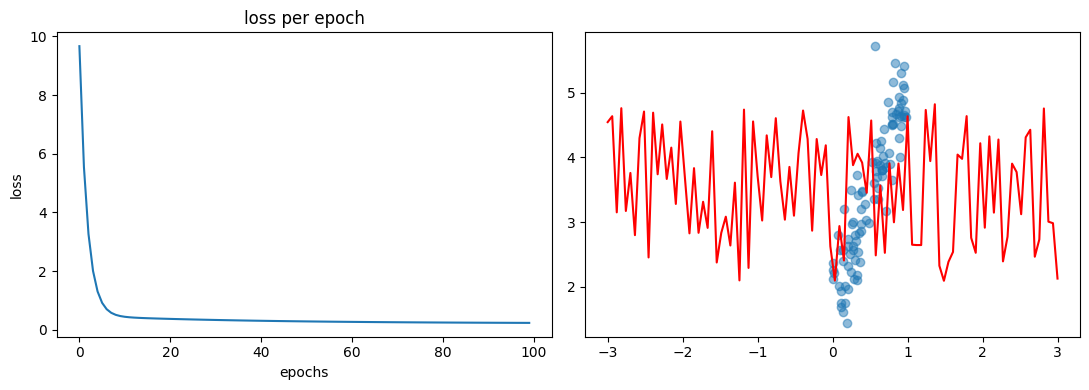

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(losses)
axes[0].set_title("loss per epoch")
axes[0].set_xlabel("epochs")
axes[0].set_ylabel("loss")

axes[1].scatter(X, y_true, alpha=0.5) # didn't understand it!
xs = torch.linspace(-3, 3, 100).reshape(-1, 1)
axes[1].plot(xs, (X@W+b).detach(), color="red")

plt.tight_layout()
plt.show()

In [ ]:
#using optimizer
torch.manual_seed(42)

X = torch.rand(100, 1)
W = torch.rand(1,1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer = torch.optim.SGD([W,b], lr=0.1)
y_true = 3 * X + 2 + (0.5 * torch.randn(100,1)) # later part is to add a little noise in the data
l_r = 0.1
losses = []
for epoch in range(1, 101):
  y_pred = X @ W + b
  loss = ((y_pred - y_true) ** 2).mean()
  optimizer.zero_grad() #sets w.grad and b.gras as 0
  loss.backward()
  optimizer.step() #updates w and b easily without pausing thier gradients
  #same answer but just 3 clean lines
  losses.append(loss.item())
  if epoch % 20 == 0:
    print("epoch: ", epoch, ", loss: ", loss.item())
print("final W, b are: ", W.item(), ", ", b.item())

epoch:  20 , loss:  0.3708063066005707
epoch:  40 , loss:  0.30465877056121826
epoch:  60 , loss:  0.26611262559890747
epoch:  80 , loss:  0.24361154437065125
epoch:  100 , loss:  0.2304767370223999
final W, b are:  2.7954623699188232 ,  2.079314947128296


tensor(14.)
final W, b, loss (for lr=0.1):  2.2918035984039307  , 0.14178697764873505  , 0.6033958792686462
final W, b, loss (for lr=0.1):  -1.4123311042785645  , 0.24511361122131348  , 8.295129776000977
final W, b, loss (for lr=0.1):  -12.918502807617188  , -524.7818603515625  , 68884.9921875
final W, b, loss (for lr=0.1):  0.5549319386482239  , 0.40644371509552  , 0.5274587869644165


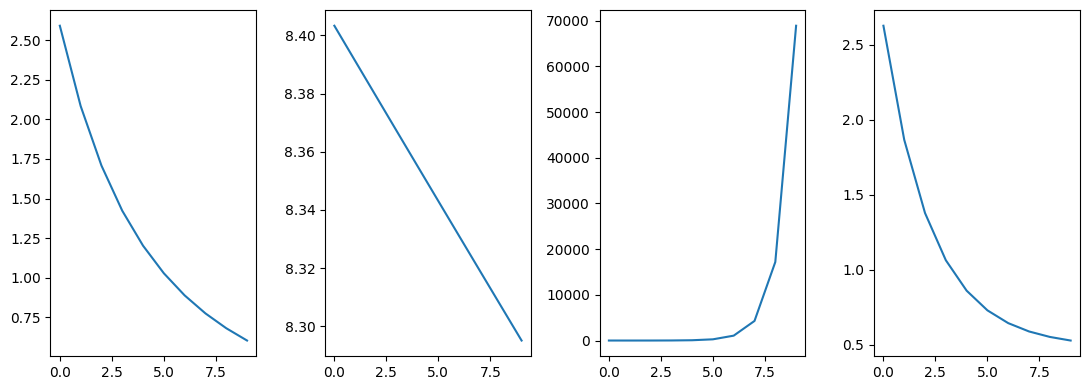

In [ ]:
'''
quiz question: "
1. What does loss.backward() compute, and where are the results stored?
2. Why must you zero the gradients every iteration? What happens if you forget?
3. Why is the weight update wrapped in torch.no_grad()?
4. What happens in gradient descent if lr is far too large? Far too small?
5. With w = 1, b = 0, x = 2, target = 5 and loss = (w*x + b - target)**2, compute dL/dw and dL/db by hand first, then verify with autograd.
"

quiz answers: "
1. loss.backward() computes dloss/dW and dloss/db (or any other tensor which has requires_grad=True) and the results are stored in the tensors .grad parameter, like W.grad, or b.grad.
2. if there are multiple epochs then we must zero the gradient else the previous epoch's gradient will carry forward and will interfere with finding the minima direction for loss w.r.t. W and b.
3. when we do requires_grad=True then for that tensor all the calculations it's a part of is recorded so to later calculate gradient of it. since we don't want the W updating stuff to be considered for dloss/dW, we do torch.no_grad()
4. if lr is too large the gradient will surpass the minima W value and jump over it, and it will keep jumping without or very slow converging to minima point. for lr being very less, it will converge most of the times but very slowly, in millions of epochs to get W such that loss in minimum!
5. dloss/dw = dloss/dy_pred * dy_pred/dw = 2(y_pred - y_true) * x = 2(2-5) * 2 = -12 now w would be w = 1 - 0.1 * (-12) = 2.2
"

exercises: "
1. For f(x) = x**3 + 2*x at x = 2, work out the derivative by hand, then confirm it with autograd.
2. Rerun the line-fitting loop with lr = 0.001, lr = 0.1 and lr = 1.5. Predict what each loss curve looks like, then plot all three together. (Hint: reset w and b at the start of each run.)
3. Change the data to a curve: y_true = x ** 2 + 0.5 * torch.randn(100, 1), then fit the same straight line. Look at the fitted line and the final loss. Why can’t it fit? What do you think a neural network adds to fix this?
"

exercises answers:
exercise 1 and 2 and 3
'''
a = torch.tensor(2., requires_grad=True)
f = a**3 + 2*a
f.backward()
print(a.grad)


fig, axes = plt.subplots(1, 4, figsize=(11,4))
X = torch.randn(10,1)
W = torch.randn(1, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer = torch.optim.SGD([W, b], lr = 0.1)
y_true = X**3 + 2*X
losses = []
epochs = 10
for epoch in range(epochs):
  y_pred = X @ W + b
  loss = ((y_pred - y_true)**2).mean()
  losses.append(loss.item())
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
print("final W, b, loss (for lr=0.1): ", W.item(), " ,", b.item(), " ,", loss.item())
axes[0].plot(losses)

losses = []
W = torch.randn(1, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer = torch.optim.SGD([W, b], lr = 0.001)
for epoch in range(epochs):
  y_pred = X @ W + b
  loss = ((y_pred - y_true)**2).mean()
  losses.append(loss.item())
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
print("final W, b, loss (for lr=0.1): ", W.item(), " ,", b.item(), " ,", loss.item())
axes[1].plot(losses)

losses = []
W = torch.randn(1, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer = torch.optim.SGD([W, b], lr = 1.5)
for epoch in range(epochs):
  y_pred = X @ W + b
  loss = ((y_pred - y_true)**2).mean()
  losses.append(loss.item())
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
print("final W, b, loss (for lr=0.1): ", W.item(), " ,", b.item(), " ,", loss.item()) # overshoots and misses minima completely!
axes[2].plot(losses)

losses = []
W = torch.randn(1, 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
optimizer = torch.optim.SGD([W, b], lr = 0.1)
y_true = X ** 2 + 0.5 * torch.randn(10, 1)
for epoch in range(epochs):
  y_pred = X @ W + b
  loss = ((y_pred - y_true)**2).mean()
  losses.append(loss.item())
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
print("final W, b, loss (for lr=0.1): ", W.item(), " ,", b.item(), " ,", loss.item()) # overshoots and misses minima completely!
axes[3].plot(losses)

plt.tight_layout()
plt.show()